<a href="https://colab.research.google.com/github/vansestopier-codes/Ciencia-datos/blob/main/Actividad5Preprocesamiento.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 5**
Preprocesamiento de datos

---

*   NOMBRE: VANESSA ESTOPIER TINAJERO
*   MATRÍCULA: A01841600

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


En esta actividad trabajarás con el archivo `heart_disease.csv`, basado en un conjunto de datos sobre pacientes y variables clínicas relacionadas con enfermedades cardíacas, disponible en Kaggle.

Los datos fueron recopilados para analizar la presencia de enfermedades cardíacas en los pacientes y contienen información demográfica, clínica y resultados de pruebas diagnósticas. Los indicadores incluidos son:

* `id`: Identificador único de cada paciente
* `age`: Edad del paciente en años
* `origin`: Lugar de estudio
* `sex`: Masculino / Femenino
* `cp`: Tipo de dolor torácico (angina típica, angina atípica, no anginal, asintomático)
* `trestbps`: Presión arterial en reposo (en mm Hg al ingreso al hospital)
* `chol`: Colesterol sérico en mg/dl
* `fbs`: Si el azúcar en ayunas > 120 mg/dl
* `restecg`: Resultados del electrocardiograma en reposo (normal, anomalía ST-T, hipertrofia ventricular izquierda)
* `thalach`: Frecuencia cardíaca máxima alcanzada
* `exang`: Angina inducida por ejercicio (Verdadero / Falso)
* `oldpeak`: Depresión del segmento ST inducida por ejercicio respecto al reposo
* `slope`: Pendiente del segmento ST en el pico de ejercicio
* `ca`: Número de vasos principales coloreados por fluoroscopía (0 - 3)
* `thal`: Resultado de la prueba de perfusión cardíaca (normal, defecto fijo, defecto reversible)
* `num`: Indica si el paciente tiene o no enfermedad cardíaca, o el grado de enfermedad (0 = sano, 1 - 4 = enfermedad) Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo.

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [2]:
# Importar las bibliotecas necesarias
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.impute import SimpleImputer

1. Descarga el archivo: `heart_disease.csv` y guarda, en un dataframe (`cardio_df`), todos sus registros.
* Haz que la columna `id` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
* Determina la cantidad de valores únicos por columna.

In [3]:
import warnings
warnings.filterwarnings("ignore")

ruta = "/content/drive/MyDrive/Colab Notebooks/MNA - CyA de Datos/5.2 Actividad 5 | Preprocesamiento/heart_disease.csv"

# Cargar el archivo en cardio_df y poner 'id' como índice
cardio_df = pd.read_csv(ruta)
cardio_df = cardio_df.set_index("id")

# Resumen de tipos de datos
cardio_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 918 entries, 1 to 920
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       918 non-null    int64  
 1   sex       918 non-null    object 
 2   origin    918 non-null    object 
 3   cp        918 non-null    object 
 4   trestbps  859 non-null    float64
 5   chol      888 non-null    float64
 6   fbs       829 non-null    object 
 7   restecg   918 non-null    object 
 8   thalch    863 non-null    float64
 9   exang     863 non-null    object 
 10  oldpeak   856 non-null    float64
 11  slope     610 non-null    object 
 12  ca        309 non-null    float64
 13  thal      434 non-null    object 
 14  num       918 non-null    int64  
dtypes: float64(5), int64(2), object(8)
memory usage: 114.8+ KB


In [4]:
# Cantidad de valores únicos por columna
cardio_df.nunique()

,0
age,50
sex,2
origin,4
cp,4
trestbps,60
chol,216
fbs,2
restecg,3
thalch,119
exang,2


**Respuesta:** Según `info()`, el dataframe tiene 918 registros y 15 columnas (sin contar `id`, que es el índice). De ellas, 7 son numéricas (`age`, `trestbps`, `chol`, `thalch`, `oldpeak`, `ca`, `num`) y 8 son de texto (`sex`, `origin`, `cp`, `fbs`, `restecg`, `exang`, `slope`, `thal`). Además, `info()` muestra valores faltantes en varias columnas, sobre todo en `slope`, `ca` y `thal`. La tabla de valores únicos muestra que `ca` (4) y `num` (5) son numéricas con muy pocos valores distintos, lo que sugiere que en realidad son categóricas codificadas como números. Esto lo revisamos en el ejercicio 2.

2. Examina las variables numéricas que presentan pocos valores únicos, ya que esto puede indicar que en realidad se tratan de variables categóricas codificadas como números.
* Si existen casos de este tipo, conviértelas a categóricas. Antes de hacerlo, revisa sus descripciones para determinar si son ordinales o nominales y, si son ordinales, establece el orden correcto de las categorías.

In [5]:
from pandas.api.types import CategoricalDtype

# 'ca' y 'num' son ordinales: se define el orden correcto de las categorías
orden_ca = CategoricalDtype(categories=[0.0, 1.0, 2.0, 3.0], ordered=True)
orden_num = CategoricalDtype(categories=[0, 1, 2, 3, 4], ordered=True)

cardio_df["ca"] = cardio_df["ca"].astype(orden_ca)
cardio_df["num"] = cardio_df["num"].astype(orden_num)

# Verificar el cambio
cardio_df[["ca", "num"]].dtypes

,0
ca,category
num,category


In [6]:
print(cardio_df["ca"].cat.categories, cardio_df["ca"].cat.ordered)
print(cardio_df["num"].cat.categories, cardio_df["num"].cat.ordered)

Index([0.0, 1.0, 2.0, 3.0], dtype='float64') True
Index([0, 1, 2, 3, 4], dtype='int64') True


3. Obtén las estadísticas descriptivas de las variables, realizando el análisis por separado para las variables numéricas y las categóricas.
* Para las numéricas, incluye el sesgo y la curtosis.
* Para las categóricas, imprime además las tablas de frecuencia.

In [7]:
# Separar columnas numéricas y categóricas
num_cols = cardio_df.select_dtypes(include="number").columns
cat_cols = cardio_df.select_dtypes(exclude="number").columns

print("Numéricas:", list(num_cols))
print("Categóricas:", list(cat_cols))

Numéricas: ['age', 'trestbps', 'chol', 'thalch', 'oldpeak']
Categóricas: ['sex', 'origin', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal', 'num']


In [8]:
# Estadísticas descriptivas de las numéricas
cardio_df[num_cols].describe()

,age,trestbps,chol,thalch,oldpeak
count,918.000000,859.000000,888.000000,863.000000,856.000000
mean,53.530501,132.294529,242.189189,137.528389,0.880607
std,9.412783,18.535875,53.424806,25.950226,1.091840
min,28.000000,80.000000,85.000000,60.000000,-2.600000
25%,47.000000,120.000000,216.000000,120.000000,0.000000
50%,54.000000,130.000000,223.000000,140.000000,0.500000
75%,60.000000,140.000000,268.000000,157.000000,1.500000
max,77.000000,200.000000,603.000000,202.000000,6.200000


In [9]:
# Sesgo y curtosis
pd.DataFrame({
    "sesgo": cardio_df[num_cols].skew(),
    "curtosis": cardio_df[num_cols].kurt()
})

,sesgo,curtosis
age,-0.193710,-0.382511
trestbps,0.630411,0.632992
chol,1.640672,6.573848
thalch,-0.209319,-0.483939
oldpeak,1.037990,1.119834


In [10]:
# Estadísticas descriptivas de las categóricas
cardio_df[cat_cols].describe()

,sex,origin,cp,fbs,restecg,exang,slope,ca,thal,num
count,918,918,918,829,918,863,610,309.0,434,918
unique,2,4,4,2,3,2,3,4.0,3,5
top,Male,Cleveland,asymptomatic,False,normal,False,flat,0.0,normal,0
freq,724,304,495,691,551,526,345,181.0,196,411


In [11]:
# Tablas de frecuencia de cada variable categórica (incluye los faltantes)
for col in cat_cols:
    print(f"--- {col} ---")
    print(cardio_df[col].value_counts(dropna=False))
    print()

--- sex ---
sex
Male      724
Female    194
Name: count, dtype: int64

--- origin ---
origin
Cleveland        304
Hungary          292
VA Long Beach    200
Switzerland      122
Name: count, dtype: int64

--- cp ---
cp
asymptomatic       495
non-anginal        204
atypical angina    174
typical angina      45
Name: count, dtype: int64

--- fbs ---
fbs
False    691
True     138
NaN       89
Name: count, dtype: int64

--- restecg ---
restecg
normal              551
lv hypertrophy      188
st-t abnormality    179
Name: count, dtype: int64

--- exang ---
exang
False    526
True     337
NaN       55
Name: count, dtype: int64

--- slope ---
slope
flat           345
NaN            308
upsloping      202
downsloping     63
Name: count, dtype: int64

--- ca ---
ca
NaN     609
 0.0    181
 1.0     67
 2.0     41
 3.0     20
Name: count, dtype: int64

--- thal ---
thal
NaN                  484
normal               196
reversable defect    192
fixed defect          46
Name: count, dtype: int64

---

**Variables numéricas:**
- `age`: media de 53.5 años (rango de 28 a 77). Su distribución es casi simétrica (sesgo ≈ -0.19) y un poco más plana que una normal (curtosis ≈ -0.38).
- `trestbps`: media de 132.3 mm Hg y máximo de 200. Tiene un sesgo positivo moderado (0.63), por algunos valores altos.
- `chol`: es la variable con la distribución más irregular. Tiene un sesgo positivo alto (1.64) y una curtosis muy alta (6.57), lo que indica colas pesadas y la presencia de valores extremos (máximo de 603 mg/dl, mientras la mediana es 223). Más adelante, al revisar atípicos, volveremos a ella.
- `thalch`: media de 137.5, con sesgo ligeramente negativo (-0.21) y curtosis cercana a cero (-0.48). Es casi simétrica.
- `oldpeak`: sesgo positivo (1.04), porque la mayoría de los pacientes tiene valores cercanos a 0 (369 pacientes tienen 0) y unos pocos tienen valores altos, hasta 6.2. También tiene valores negativos (mínimo de -2.6).

**Variables categóricas:**
Las tablas de frecuencia muestran que hay más hombres (724) que mujeres (194), que el tipo de dolor más frecuente es el asintomático (495) y que el origen con más pacientes es Cleveland (304). Las variables `slope`, `ca` y `thal` tienen muchos valores faltantes (308, 609 y 484 respectivamente), por lo que se tratarán en el ejercicio 4.

4. Calcula el porcentaje de valores faltantes en cada columna.
* Elimina aquellas columnas cuyo porcentaje de valores faltantes supere el 30%.
* Crea un mapa de calor que visualice la distribución de los valores faltantes en todas las columnas restantes.
* Algunas variables presentan valores faltantes de manera simultánea; es decir, en el mapa se pueden identificar filas donde varias están ausentes al mismo tiempo. Enumera cuáles son dichas variables e investiga si esta concurrencia tiene sentido desde un punto de vista médico o clínico.

In [12]:
# Porcentaje de valores faltantes por columna
porcentaje_faltantes = cardio_df.isnull().mean() * 100
porcentaje_faltantes.sort_values(ascending=False)

,0
ca,66.339869
thal,52.723312
slope,33.551198
fbs,9.694989
oldpeak,6.753813
trestbps,6.427015
thalch,5.991285
exang,5.991285
chol,3.267974
sex,0.000000


In [13]:
# Eliminar columnas con más de 30% de faltantes
cols_eliminar = porcentaje_faltantes[porcentaje_faltantes > 30].index
print("Columnas eliminadas:", list(cols_eliminar))

cardio_df = cardio_df.drop(columns=cols_eliminar)
cardio_df.shape

Columnas eliminadas: ['slope', 'ca', 'thal']


(918, 12)

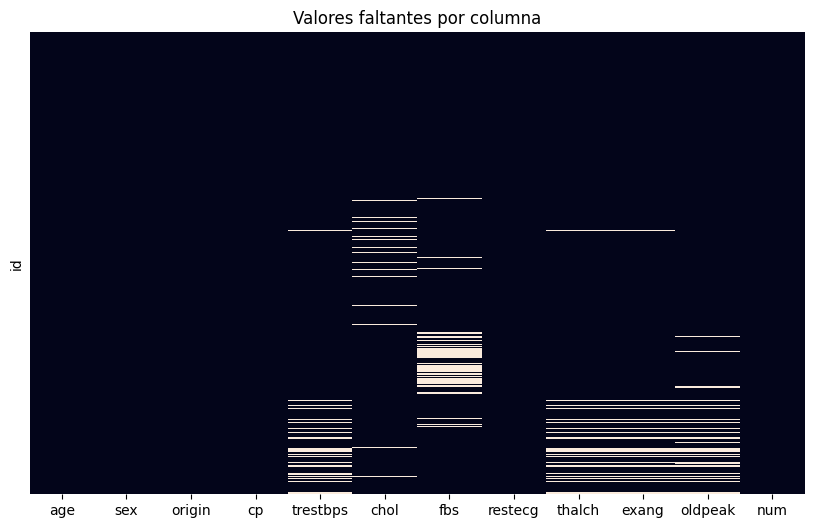

In [14]:
# Mapa de calor de valores faltantes
plt.figure(figsize=(10, 6))
sns.heatmap(cardio_df.isnull(), cbar=False, yticklabels=False)
plt.title("Valores faltantes por columna")
plt.show()

In [15]:
# ¿De qué origen son los pacientes con thalch faltante?
cardio_df[cardio_df["thalch"].isnull()]["origin"].value_counts()

,count
origin,
VA Long Beach,53
Hungary,1
Switzerland,1


**Porcentaje de faltantes:** Las columnas `ca` (66.3%), `thal` (52.7%) y `slope` (33.5%) superan el 30% de valores faltantes, por lo que fueron eliminadas. Las demás columnas tienen menos de 10% de faltantes: `fbs` (9.7%), `oldpeak` (6.8%), `trestbps` (6.4%), `thalch` y `exang` (6.0%) y `chol` (3.3%).

**Faltantes simultáneos:** En el mapa de calor se observa que `trestbps`, `thalch`, `exang` y `oldpeak` están ausentes en las mismas filas. De los 55 pacientes con `thalch` faltante, los 55 también carecen de `exang` y `trestbps`, y 54 también de `oldpeak`.

**Sentido clínico:** `thalch` (frecuencia cardíaca máxima), `exang` (angina inducida por ejercicio) y `oldpeak` (depresión del segmento ST inducida por ejercicio) provienen de la misma prueba de esfuerzo. Si la prueba no se realizó, las tres mediciones faltan al mismo tiempo, por lo que esta concurrencia sí tiene sentido médico. La presión en reposo (`trestbps`) se registra en el ingreso y no depende de esa prueba, pero también falta en esos mismos pacientes, lo que sugiere un registro clínico incompleto en esos casos. 53 de esos 55 pacientes pertenecen al origen "VA Long Beach", lo que apunta a que el patrón está relacionado con el centro donde se recopilaron los datos.

5. Si centramos el análisis en una de las variables identificadas en el ejercicio anterior, se puede suponer que los hallazgos obtenidos podrían ser aplicables a las demás variables que presentan un patrón similar.

* ¿Tendrán los valores faltantes de `thalch` relación con alguna otra variable? Analízalo considerando las siguientes columnas:
  *   Numéricas: `age`, `chol`
  *   Categóricas: `restecg`, `cp`

Para ello deberás dividir cada columna en dos grupos: con / sin faltantes en `thalch` y utilizar métodos gráficos y pruebas de hipótesis para ver si hay diferencias significativas.
* Incluye las conclusiones del análisis con los resultados obtenidos.
* Justifica si el mecanismo de faltantes de `thalch` es MCAR (*Missing Completely at Random*) o MAR (*Missing at Random*).

**NOTA**. Puedes reutilizar las funciones `Diagnose_MV_Numerical` y `Diagnose_MV_Categorical` definidas en Hands-On-Prep_Missing_Values.zip. Revisa nuevamente cómo utilizarlas.

In [16]:
from scipy.stats import ttest_ind
def Diagnose_MV_Numerical(df,str_att_name,BM_MV):
    MV_labels = {True:'With Missing Values',False:'Without Missing Values'}

    labels=[]
    box_sr = pd.Series('',index = BM_MV.unique())
    for poss in BM_MV.unique():
        BM = BM_MV == poss
        box_sr[poss] = df[BM][str_att_name].dropna()
        labels.append(MV_labels[poss])

    plt.boxplot(box_sr,vert=False)
    plt.yticks([1,2],labels)
    plt.xlabel(str_att_name)
    plt.show()

    plt.figure(figsize=(10,4))

    att_range = (df[str_att_name].min(),df[str_att_name].max())

    for i,poss in enumerate(BM_MV.unique()):
        plt.subplot(1,2,i+1)
        BM = BM_MV == poss
        df[BM][str_att_name].hist()
        plt.xlim = att_range
        plt.xlabel(str_att_name)
        plt.title(MV_labels[poss])

    plt.show()

    group_1_data = df[BM_MV][str_att_name].dropna()
    group_2_data = df[~BM_MV][str_att_name].dropna()

    p_value = ttest_ind(group_1_data,group_2_data).pvalue

    print('p-value of t-test: {}'.format(p_value))

In [17]:
from scipy.stats import chi2_contingency
def Diagnose_MV_Categorical(df,str_att_name,BM_MV):
    MV_labels = {True:'With Missing Values',False:'Without Missing Values'}

    plt.figure(figsize=(10,4))
    for i,poss in enumerate(BM_MV.unique()):
        plt.subplot(1,2,i+1)
        BM = BM_MV == poss
        df[BM][str_att_name].value_counts().plot.bar()
        plt.title(MV_labels[poss])
    plt.show()

    contigency_table = pd.crosstab(BM_MV,df[str_att_name])
    p_value = chi2_contingency(contigency_table)[1]

    print('p-value of Chi_squared test: {}'.format(p_value))

In [18]:
# True si el paciente tiene thalch faltante, False si no
BM_MV = cardio_df["thalch"].isnull()
BM_MV.value_counts()

,count
thalch,
False,863
True,55


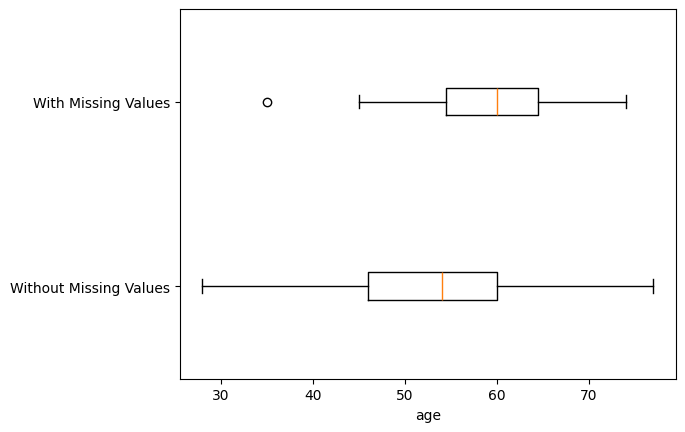

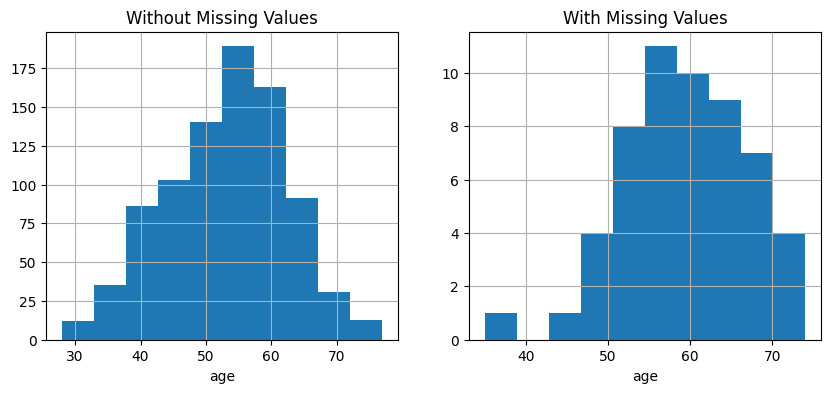

p-value of t-test: 1.5041244185890902e-06


In [19]:
Diagnose_MV_Numerical(cardio_df, "age", BM_MV)

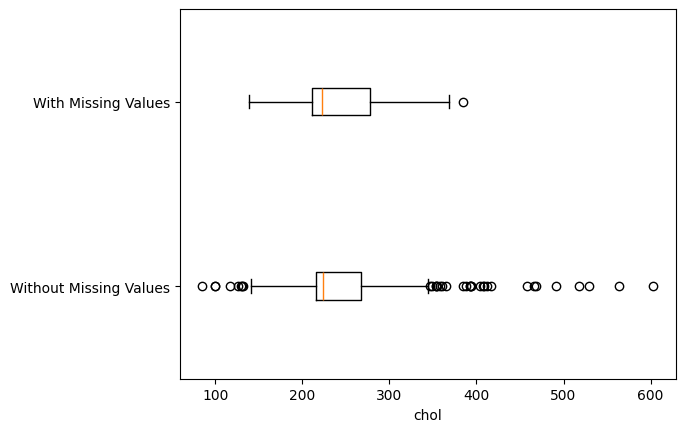

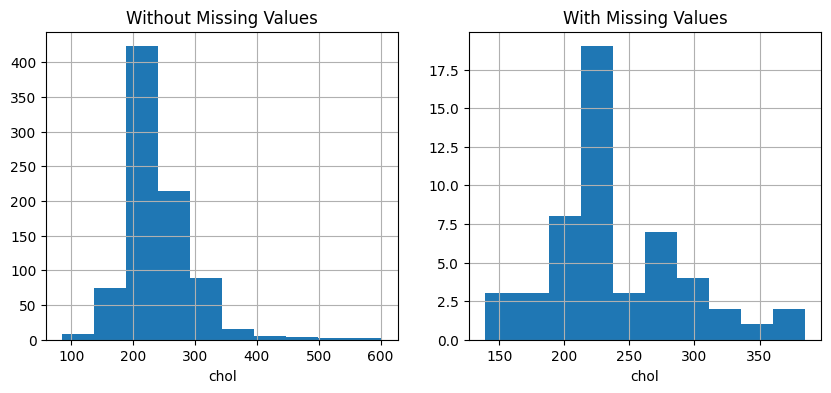

p-value of t-test: 0.7165289974295672


In [20]:
Diagnose_MV_Numerical(cardio_df, "chol", BM_MV)

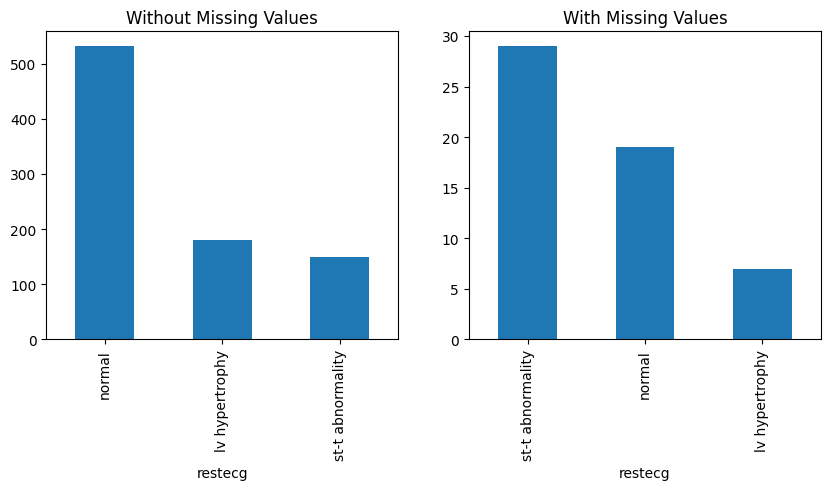

p-value of Chi_squared test: 1.1472889573985467e-09


In [21]:
Diagnose_MV_Categorical(cardio_df, "restecg", BM_MV)

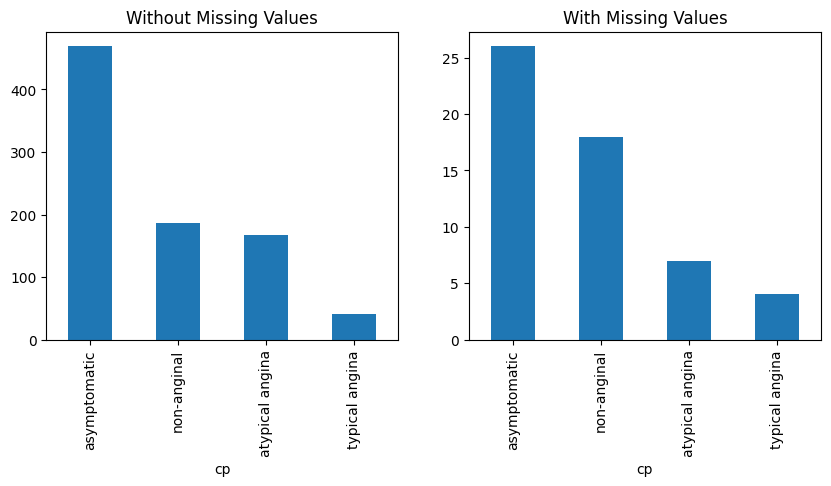

p-value of Chi_squared test: 0.15420097177251701


In [22]:
Diagnose_MV_Categorical(cardio_df, "cp", BM_MV)

**Conclusiones del análisis de los faltantes de `thalch`:**

Se dividió a los pacientes en dos grupos (con y sin `thalch` faltante) y se compararon en las cuatro variables solicitadas, con gráficas y pruebas de hipótesis (t-test para las numéricas y chi-cuadrada para las categóricas, con un nivel de significancia de 0.05).

- **`age` (numérica):** El p-value del t-test es de 1.5e-06, por lo que **sí hay diferencia significativa**. Los pacientes con `thalch` faltante son mayores: su mediana es de 60 años, contra 54 de los pacientes sin faltante. El boxplot y el histograma muestran el mismo corrimiento hacia edades mayores.
- **`chol` (numérica):** El p-value es de 0.717, por lo que **no hay diferencia significativa**. Ambos grupos tienen distribuciones y medianas muy parecidas (223 y 224 mg/dl).
- **`restecg` (categórica):** El p-value de la prueba chi-cuadrada es de 1.1e-09, por lo que **sí hay diferencia significativa**. Entre los pacientes con `thalch` faltante, la categoría más frecuente es "anomalía ST-T" (53%), mientras que en los pacientes sin faltante la más frecuente es "normal" (62%).
- **`cp` (categórica):** El p-value es de 0.154, por lo que **no hay diferencia significativa**. La distribución de tipos de dolor es similar en ambos grupos.

**Mecanismo de los faltantes:** Concluyo que los valores faltantes de `thalch` son **MAR (Missing at Random)** y no MCAR. Si fueran MCAR, la ausencia no dependería de ninguna otra variable y los dos grupos serían parecidos en todas las columnas. Sin embargo, la presencia de faltantes en `thalch` se relaciona de forma significativa con variables observadas (`age` y `restecg`). Por eso la probabilidad de que falte `thalch` puede explicarse con otras variables del conjunto de datos, que es la definición de MAR.

Cabe aclarar que con los datos disponibles no se puede descartar por completo un mecanismo MNAR (que dependa del propio valor faltante de `thalch`), porque ese valor no se observa. Además, como en el ejercicio 4 se vio que casi todos los faltantes provienen del origen "VA Long Beach", es probable que parte de estas diferencias se deba al centro donde se recopilaron los datos.

Como `trestbps`, `exang` y `oldpeak` presentan el mismo patrón de ausencia simultánea, se puede suponer que estos hallazgos aplican también a ellas.

6. La imputación de una variable con valores faltantes puede realizarse por grupos o segmentos relevantes. Esto significa que, en lugar de utilizar una estadística global de toda la columna, se calcula la estadística correspondiente dentro de cada grupo definido por otra variable, haciendo:

> `df['var_with_missing'] = df.groupby('related_var')['var_with_missing'].transform(lambda x: x.fillna(x.median()))`

* Utiliza la variable `restecg` para separar los grupos e imputar `thalch` y todas las variables con patrón de faltantes similar (identificadas en el ejercicio 4) Asegúrate de cambiar la función de agregado si hay variables no numéricas.
* Vuelve a generar el mapa de calor para verificar que los valores faltantes en estas variables hayan sido imputados.

In [23]:
# Imputar las numéricas con la mediana de cada grupo de restecg
for col in ["thalch", "trestbps", "oldpeak"]:
    cardio_df[col] = cardio_df.groupby("restecg")[col].transform(lambda x: x.fillna(x.median()))

In [24]:
# exang no es numérica: se usa la moda (valor más frecuente) de cada grupo
cardio_df["exang"] = cardio_df.groupby("restecg")["exang"].transform(lambda x: x.fillna(x.mode()[0]))

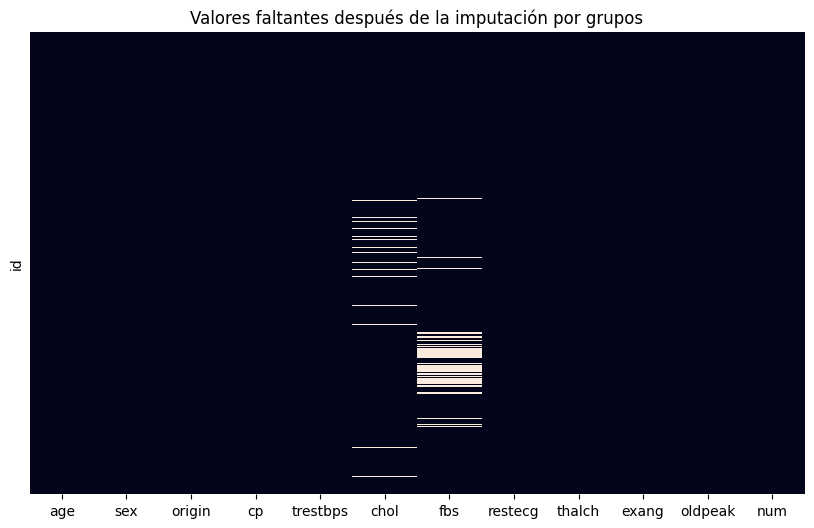

In [25]:
# Mapa de calor después de imputar
plt.figure(figsize=(10, 6))
sns.heatmap(cardio_df.isnull(), cbar=False, yticklabels=False)
plt.title("Valores faltantes después de la imputación por grupos")
plt.show()

In [26]:
cardio_df.isnull().sum()

,0
age,0
sex,0
origin,0
cp,0
trestbps,0
chol,30
fbs,89
restecg,0
thalch,0
exang,0


**Imputación por grupos:** Se utilizó `restecg` para separar a los pacientes en grupos (normal, anomalía ST-T e hipertrofia ventricular izquierda) y se imputaron `thalch`, `trestbps` y `oldpeak` con la **mediana** de su grupo, ya que son numéricas y varias de ellas tienen sesgo y valores extremos, y la mediana es más robusta que la media. Para `exang`, que es una variable verdadero/falso (no numérica), se cambió la función de agregado a la **moda** de cada grupo.

El nuevo mapa de calor muestra que `thalch`, `trestbps`, `exang` y `oldpeak` ya no tienen valores faltantes. Las únicas columnas que aún conservan faltantes son `chol` (30) y `fbs` (89), que se imputarán en el ejercicio 7.

7. Para las variables que aún presentan valores faltantes, realiza la imputación utilizando estadísticas generales calculadas sobre toda la columna, sin segmentar por grupos. Esta vez utiliza la clase `SimpleImputer` de sklearn
* Justifica la estrategia (*mean, median, most_frequent*) que emplees en cada caso.


In [27]:
# chol es numérica con sesgo alto y valores extremos: se usa la mediana
imputer_chol = SimpleImputer(strategy="median")
cardio_df[["chol"]] = imputer_chol.fit_transform(cardio_df[["chol"]])

print("Mediana usada para chol:", imputer_chol.statistics_[0])

Mediana usada para chol: 223.0


In [28]:
# fbs es verdadero/falso (no numérica): se usa el valor más frecuente
imputer_fbs = SimpleImputer(strategy="most_frequent")
cardio_df[["fbs"]] = imputer_fbs.fit_transform(cardio_df[["fbs"]])

print("Valor más frecuente usado para fbs:", imputer_fbs.statistics_[0])

Valor más frecuente usado para fbs: False


In [29]:
cardio_df.isnull().sum()

,0
age,0
sex,0
origin,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalch,0
exang,0


**Imputación global con SimpleImputer:** Las dos variables que aún tenían faltantes eran `chol` (30) y `fbs` (89). En ambos casos se usó una estadística calculada sobre toda la columna.

- **`chol` → `median`:** Es una variable numérica con sesgo positivo alto (1.64) y curtosis muy alta (6.57), es decir, tiene valores extremos (hasta 603 mg/dl). La media se ve afectada por esos valores, mientras que la mediana (223 mg/dl) es más robusta y representa mejor el valor típico.
- **`fbs` → `most_frequent`:** Es una variable de dos categorías (verdadero/falso), por lo que no se puede calcular una media ni una mediana con sentido. Se usó la moda, es decir, el valor más frecuente (`False`, que corresponde a pacientes con azúcar en ayunas menor o igual a 120 mg/dl).

Después de la imputación, el dataframe ya no tiene valores faltantes.

8. Dibuja boxplots de todas las variables numéricas.
* Obtén los valores atípicos mediante el método gráfico, a partir del objeto devuelto por el boxplot.

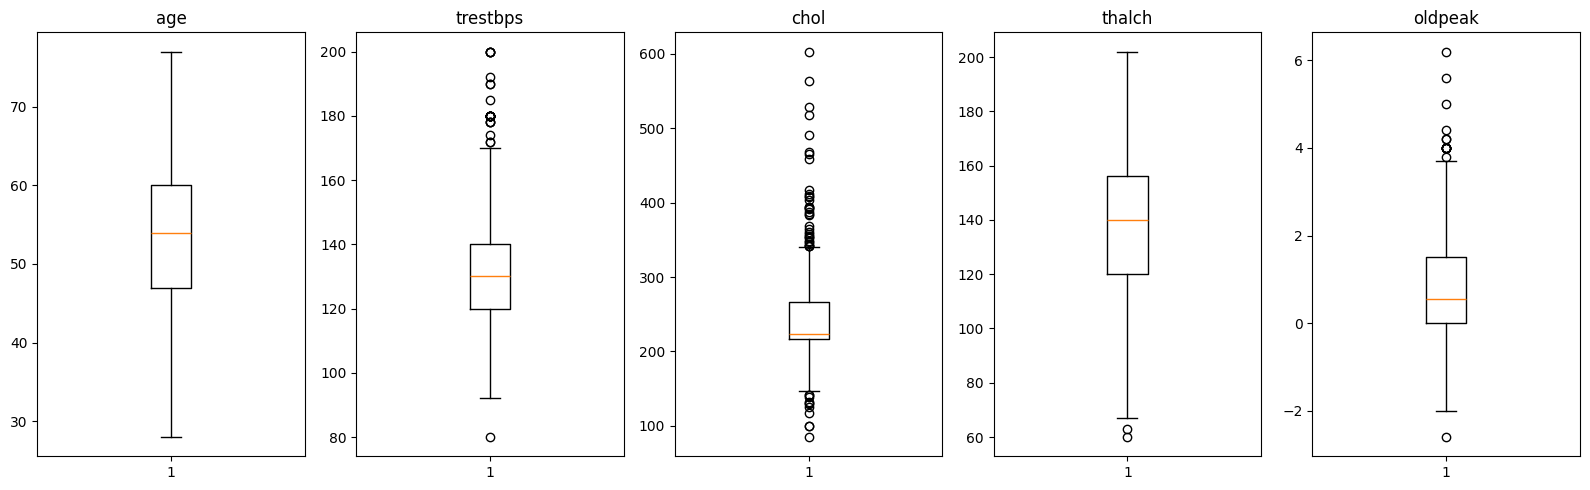

In [30]:
# Variables numéricas actuales
num_cols = cardio_df.select_dtypes(include="number").columns

fig, axes = plt.subplots(1, len(num_cols), figsize=(16, 5))
atipicos_grafico = {}

for ax, col in zip(axes, num_cols):
    bp = ax.boxplot(cardio_df[col])          # bp es el objeto que devuelve el boxplot
    ax.set_title(col)
    atipicos_grafico[col] = bp["fliers"][0].get_ydata()   # los atípicos están en 'fliers'

plt.tight_layout()
plt.show()

In [31]:
for col, valores in atipicos_grafico.items():
    print(f"{col}: {len(valores)} valores atípicos")

age: 0 valores atípicos
trestbps: 27 valores atípicos
chol: 44 valores atípicos
thalch: 2 valores atípicos
oldpeak: 16 valores atípicos


In [32]:
sorted(atipicos_grafico["trestbps"])

[np.float64(80.0),
 np.float64(172.0),
 np.float64(172.0),
 np.float64(174.0),
 np.float64(178.0),
 np.float64(178.0),
 np.float64(178.0),
 np.float64(180.0),
 np.float64(180.0),
 np.float64(180.0),
 np.float64(180.0),
 np.float64(180.0),
 np.float64(180.0),
 np.float64(180.0),
 np.float64(180.0),
 np.float64(180.0),
 np.float64(180.0),
 np.float64(180.0),
 np.float64(180.0),
 np.float64(185.0),
 np.float64(190.0),
 np.float64(190.0),
 np.float64(192.0),
 np.float64(200.0),
 np.float64(200.0),
 np.float64(200.0),
 np.float64(200.0)]

**Valores atípicos (método gráfico):** Se dibujaron los boxplots de las cinco variables numéricas (`age`, `trestbps`, `chol`, `thalch` y `oldpeak`) y se obtuvieron los valores atípicos a partir del elemento `fliers` del objeto devuelto por el boxplot.

- `age`: 0 atípicos.
- `trestbps`: 27 atípicos.
- `chol`: 44 atípicos, la variable con más valores extremos, lo cual es consistente con su sesgo y curtosis altos.
- `thalch`: 2 atípicos.
- `oldpeak`: 16 atípicos.

9. Para la variable `trestbps`, calcula los valores atípicos utilizando el método del rango intercuartílico (IQR).
* Para ello obtén los cuartiles necesarios y determina los límites superior e inferior para filtrar los valores que se encuentren fuera de ese rango.
* Verifica si los resultados coinciden con los obtenidos en el ejercicio anterior.

In [33]:
# Cuartiles de trestbps
Q1 = cardio_df["trestbps"].quantile(0.25)
Q3 = cardio_df["trestbps"].quantile(0.75)
IQR = Q3 - Q1

# Límites inferior y superior
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Límite inferior:", limite_inferior)
print("Límite superior:", limite_superior)

Q1: 120.0
Q3: 140.0
IQR: 20.0
Límite inferior: 90.0
Límite superior: 170.0


In [34]:
# Valores que quedan fuera de los límites
atipicos_iqr = cardio_df[(cardio_df["trestbps"] < limite_inferior) |
                         (cardio_df["trestbps"] > limite_superior)]["trestbps"]

print("Cantidad de atípicos (IQR):", len(atipicos_iqr))
sorted(atipicos_iqr)

Cantidad de atípicos (IQR): 27


[80.0,
 172.0,
 172.0,
 174.0,
 178.0,
 178.0,
 178.0,
 180.0,
 180.0,
 180.0,
 180.0,
 180.0,
 180.0,
 180.0,
 180.0,
 180.0,
 180.0,
 180.0,
 180.0,
 185.0,
 190.0,
 190.0,
 192.0,
 200.0,
 200.0,
 200.0,
 200.0]

In [35]:
# ¿Coinciden con los del boxplot?
np.array_equal(np.sort(atipicos_iqr.values), np.sort(atipicos_grafico["trestbps"]))

True

**Atípicos de `trestbps` con el método IQR:** Los cuartiles son Q1 = 120 y Q3 = 140, por lo que el rango intercuartílico es IQR = 20. Los límites son: inferior = 120 − 1.5 × 20 = 90 y superior = 140 + 1.5 × 20 = 170. Los valores fuera de ese intervalo son atípicos: se encontraron 27 (un valor bajo de 80 mm Hg y 26 valores altos, de 172 a 200 mm Hg).

**Comparación con el método gráfico:** Los resultados **sí coinciden** con los del ejercicio 8 (mismos 27 valores). Esto es lo esperado, porque el boxplot de matplotlib dibuja como atípicos los puntos que están más allá de 1.5 veces el IQR, que es exactamente el criterio usado aquí.

10. Elimina los valores atípicos identificados de la variable `trestbps`.
* Dibuja el boxplot final para visualizar la distribución depurada.

In [36]:
# Quedarse solo con los valores dentro de los límites del IQR
cardio_df_limpio = cardio_df[(cardio_df["trestbps"] >= limite_inferior) &
                             (cardio_df["trestbps"] <= limite_superior)]

print("Registros antes:", cardio_df.shape[0])
print("Registros después:", cardio_df_limpio.shape[0])
print("Registros eliminados:", cardio_df.shape[0] - cardio_df_limpio.shape[0])

Registros antes: 918
Registros después: 891
Registros eliminados: 27


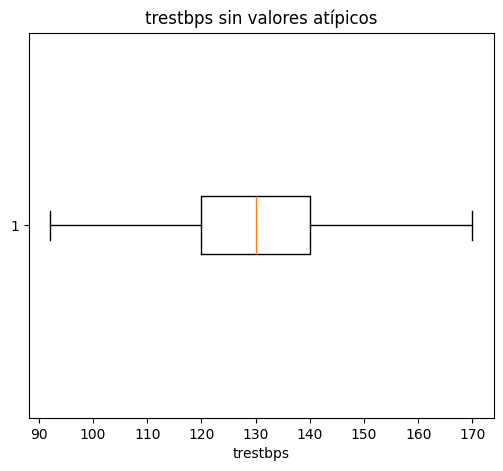

In [37]:
# Boxplot final de trestbps ya depurada
plt.figure(figsize=(6, 5))
plt.boxplot(cardio_df_limpio["trestbps"], vert=False)
plt.title("trestbps sin valores atípicos")
plt.xlabel("trestbps")
plt.show()

**Eliminación de atípicos:** Se eliminaron los 27 registros con `trestbps` fuera de los límites del IQR (menor a 90 o mayor a 170 mm Hg), por lo que el dataframe pasó de 918 a 891 registros.

El boxplot final muestra una distribución sin puntos atípicos: los valores van de 92 a 170 mm Hg y la mediana se mantiene en 130 mm Hg. Esto confirma que el filtrado fue correcto.

**Declaración de uso de IA**

Anthropic. (2026). *Claude Sonnet 5.5* [Modelo de lenguaje grande], utilizado para optimizacióny depuración. https://claude.ai/